In [ ]:
# ACTIVITY 1: DATASET PREPARATION

# **Subject:** Foundations & Data Preparation

# **Dataset Name:** Titanic Dataset

# **Dataset Source:** Data Science Dojo – GitHub

# **Source Link:** https://github.com/datasciencedojo/datasets/blob/master/titanic.csv

# **File Type:** CSV (Comma-Separated Values)

# **Original Dataset Dimensions:** 891 Rows × 12 Columns

# **Tools Used:**
# - Python
# - Google Colab
# - Pandas
# - NumPy
# - Matplotlib
# - Seaborn
# - Scikit-learn

# **Objective:** To inspect, clean, analyze and prepare a dataset for future machine learning applications.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df=pd.read_csv("titanic.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical Columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [8]:
print(df['Survived'].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [9]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [10]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

print(missing_report)

             Missing Values  Missing Percentage
PassengerId               0            0.000000
Survived                  0            0.000000
Pclass                    0            0.000000
Name                      0            0.000000
Sex                       0            0.000000
Age                     177           19.865320
SibSp                     0            0.000000
Parch                     0            0.000000
Ticket                    0            0.000000
Fare                      0            0.000000
Cabin                   687           77.104377
Embarked                  2            0.224467


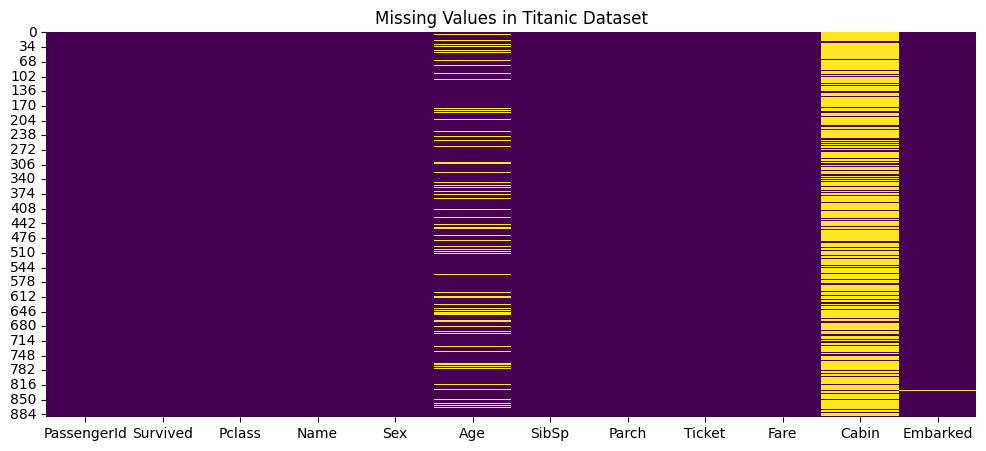

In [11]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis'
)

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [12]:
df_clean = df.copy()

In [13]:
df_clean['Age'] = df_clean['Age'].fillna(
    df_clean['Age'].median()
)

In [14]:
df_clean['Embarked'] = df_clean['Embarked'].fillna(
    df_clean['Embarked'].mode()[0]
)

In [15]:
df_clean.drop(columns=['Cabin'], inplace=True)

In [16]:
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [17]:
print("Duplicate Rows:", df_clean.duplicated().sum())

Duplicate Rows: 0


In [18]:
df_clean.drop_duplicates(inplace=True)

print("Duplicates After Cleaning:",
      df_clean.duplicated().sum())

Duplicates After Cleaning: 0


In [19]:
print(df_clean['Sex'].unique())

print(df_clean['Embarked'].unique())

['male' 'female']
['S' 'C' 'Q']


In [20]:
df_clean['Sex'] = df_clean['Sex'].str.strip().str.lower()

df_clean['Embarked'] = (
    df_clean['Embarked'].str.strip().str.upper()
)

print("Categorical values standardized.")

Categorical values standardized.


In [21]:
print(df_clean.describe())

       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  891.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.361582    0.523008   
std     257.353842    0.486592    0.836071   13.019697    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   22.000000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   35.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


Sex
male      577
female    314
Name: count, dtype: int64


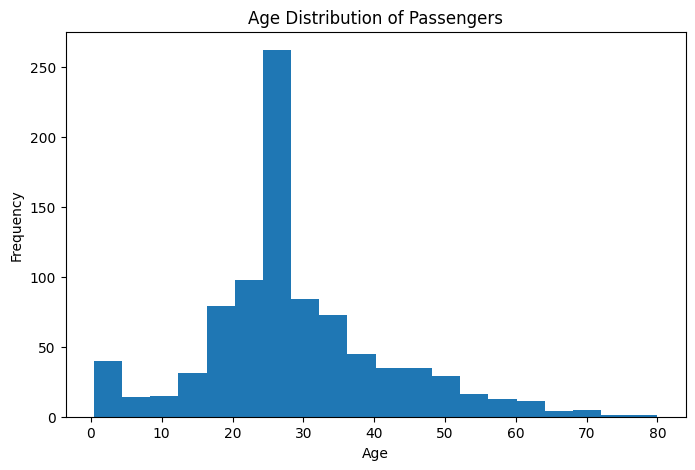

In [22]:
print(df_clean['Sex'].value_counts())
plt.figure(figsize=(8, 5))

plt.hist(df_clean['Age'], bins=20)

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

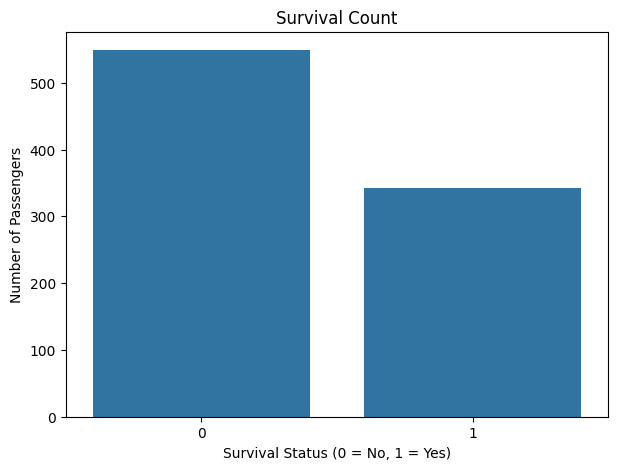

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x='Survived'
)

plt.title("Survival Count")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

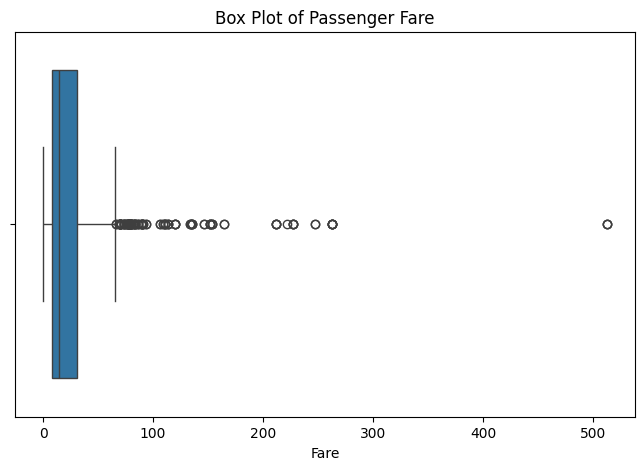

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df_clean['Fare'])

plt.title("Box Plot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

In [25]:
df_clean.drop(
    columns=['PassengerId', 'Name', 'Ticket'],
    inplace=True
)

print(df_clean.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


In [26]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['Sex', 'Embarked'],
    drop_first=True,
    dtype=int
)

print("Dataset After Encoding:")
print(df_encoded.head())

Dataset After Encoding:
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_male  Embarked_Q  \
0         0       3  22.0      1      0   7.2500         1           0   
1         1       1  38.0      1      0  71.2833         0           0   
2         1       3  26.0      0      0   7.9250         0           0   
3         1       1  35.0      1      0  53.1000         0           0   
4         0       3  35.0      0      0   8.0500         1           0   

   Embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  


In [27]:
print(df_encoded.columns.tolist())

['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


In [28]:
scaler = StandardScaler()

numerical_features = [
    'Pclass',
    'Age',
    'SibSp',
    'Parch',
    'Fare'
]

df_encoded[numerical_features] = scaler.fit_transform(
    df_encoded[numerical_features]
)

print("Numerical Features Scaled Successfully!")

print(df_encoded.head())

Numerical Features Scaled Successfully!
   Survived    Pclass       Age     SibSp     Parch      Fare  Sex_male  \
0         0  0.827377 -0.565736  0.432793 -0.473674 -0.502445         1   
1         1 -1.566107  0.663861  0.432793 -0.473674  0.786845         0   
2         1  0.827377 -0.258337 -0.474545 -0.473674 -0.488854         0   
3         1 -1.566107  0.433312  0.432793 -0.473674  0.420730         0   
4         0  0.827377  0.433312 -0.474545 -0.473674 -0.486337         1   

   Embarked_Q  Embarked_S  
0           0           1  
1           0           0  
2           0           1  
3           0           1  
4           0           1  


In [29]:
print(df_encoded[numerical_features].describe())

             Pclass           Age         SibSp         Parch          Fare
count  8.910000e+02  8.910000e+02  8.910000e+02  8.910000e+02  8.910000e+02
mean  -8.772133e-17  2.272780e-16  4.386066e-17  5.382900e-17  3.987333e-18
std    1.000562e+00  1.000562e+00  1.000562e+00  1.000562e+00  1.000562e+00
min   -1.566107e+00 -2.224156e+00 -4.745452e-01 -4.736736e-01 -6.484217e-01
25%   -3.693648e-01 -5.657365e-01 -4.745452e-01 -4.736736e-01 -4.891482e-01
50%    8.273772e-01 -1.046374e-01 -4.745452e-01 -4.736736e-01 -3.573909e-01
75%    8.273772e-01  4.333115e-01  4.327934e-01 -4.736736e-01 -2.424635e-02
max    8.273772e-01  3.891554e+00  6.784163e+00  6.974147e+00  9.667167e+00


In [30]:
df_encoded.to_csv(
    'Titanic_Prepared.csv',
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


In [31]:
from google.colab import files

files.download('Titanic_Prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
print("Final Dataset Shape:", df_encoded.shape)

print("\nRemaining Missing Values:")
print(df_encoded.isnull().sum())

print("\nDuplicate Rows:",
      df_encoded.duplicated().sum())

print("\nFinal Dataset:")
display(df_encoded.head(10))

Final Dataset Shape: (891, 9)

Remaining Missing Values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Duplicate Rows: 116

Final Dataset:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,1,0,1
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,0,0,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,0,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,0,0,1
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,1,0,1
5,0,0.827377,-0.104637,-0.474545,-0.473674,-0.478116,1,1,0
6,0,-1.566107,1.893459,-0.474545,-0.473674,0.395814,1,0,1
7,0,0.827377,-2.102733,2.247470,0.767630,-0.224083,1,0,1
8,1,0.827377,-0.181487,-0.474545,2.008933,-0.424256,0,0,1
9,1,-0.369365,-1.180535,0.432793,-0.473674,-0.042956,0,0,0


In [ ]:
## Conclusion

# The Titanic dataset was successfully inspected, cleaned and prepared for machine learning applications. Missing values were identified and handled using median and mode imputation. The Cabin column was removed due to excessive missing values.

# Duplicate records and inconsistent categorical values were checked. Exploratory Data Analysis was performed using histograms, bar charts and box plots.

# Categorical features were converted using One-Hot Encoding, and numerical features were standardized using StandardScaler.

# Finally, the prepared dataset was verified and saved separately as Titanic_Prepared.csv without modifying the original dataset.

# This activity helped in understanding the importance of data cleaning, exploratory data analysis, encoding and feature scaling in the machine learning workflow.